# Chapter 11 — Maps for a mower

Companion notebook to **Chapter 11**. Dense stereo depth on a ray-cast model of the garden, the errors of stereo
points, the ground plane of a keyframe, log-odds occupancy and lawn layers, the effect of the keyframe poses, and the
export to the Lawnmower coverage planners.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
from vslam import maps, scene, sim
from ch11_maps import (keyframe_clouds, corrected_poses, scores, draw, inside_fence,
                       SPEC, EXTENT, SIGMA_D, CMAP)
from ch10_loops import garden_keyframes, rms

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. The dense garden

`scene.Garden` is the garden of the previous chapters as solids (boxes and cylinders), plus a flower bed, a young tree
and a patio. `render_stereo` ray-casts every fourth pixel and adds disparity noise.

{'sky': 2020, 'lawn': 9711, 'border': 2306, 'fence': 7119, 'shed': 1404}


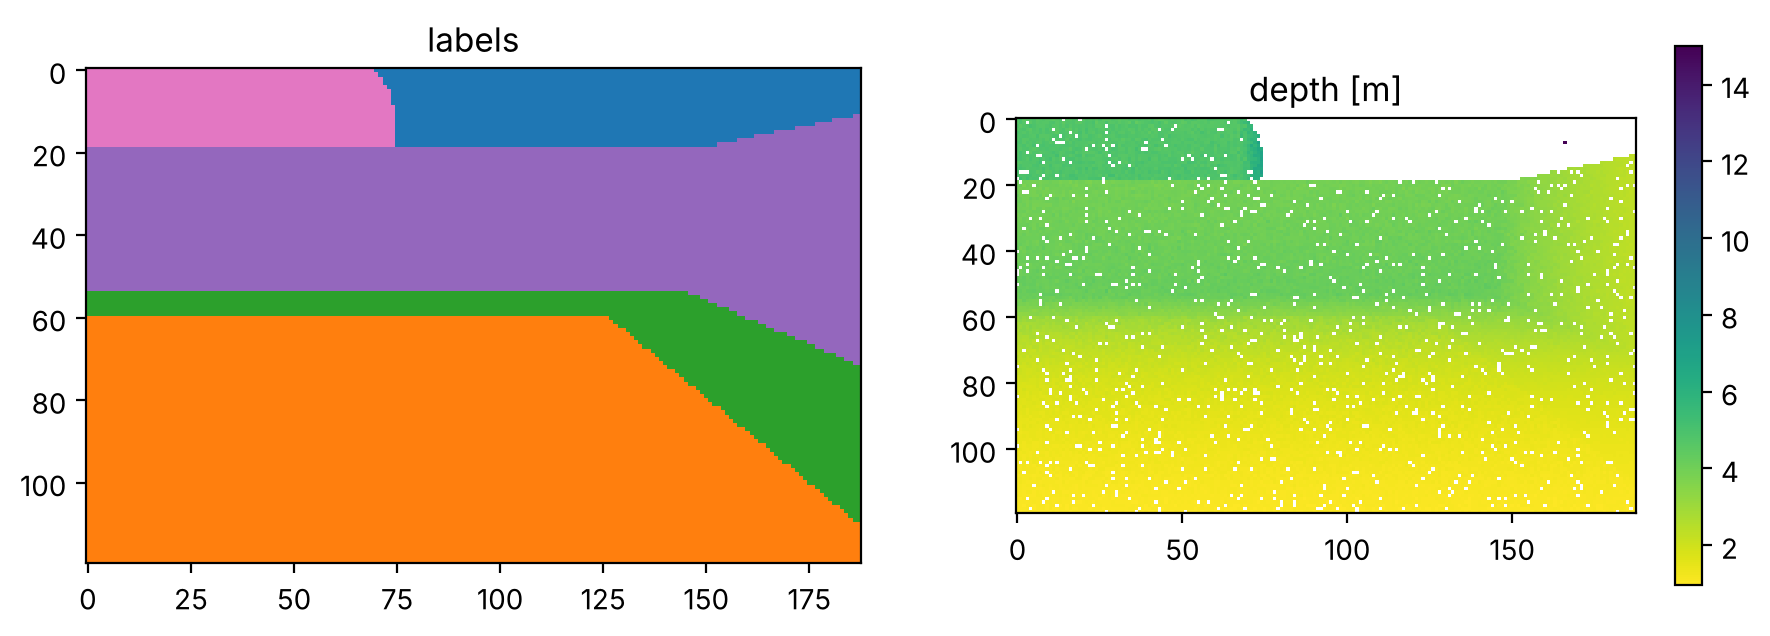

In [2]:
garden = scene.Garden()
S = sim.GardenSim()
T = sim.boustrophedon()[150] @ sim.camera_mount()
f = scene.render_stereo(garden, S.stereo, T, rng, sigma_d=SIGMA_D)
H, W = len(np.unique(f.uv[:, 1])), len(np.unique(f.uv[:, 0]))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].imshow(f.label.reshape(H, W), cmap="tab10", vmin=0, vmax=9); ax[0].set_title("labels")
im = ax[1].imshow(np.minimum(f.depth.reshape(H, W), 15), cmap="viridis_r"); ax[1].set_title("depth [m]")
fig.colorbar(im, ax=ax[1])
print({scene.LABELS[k]: int(np.sum(f.label == k)) for k in np.unique(f.label)})

## 2. Errors of stereo points (Propositions 11.2 and 11.3)

For ground points, the height error grows like $Z$ and the horizontal error like $Z^2$. Monte Carlo against the
formulas:

maximum range for a 10 cm cell (11.3): 4.283456548162944


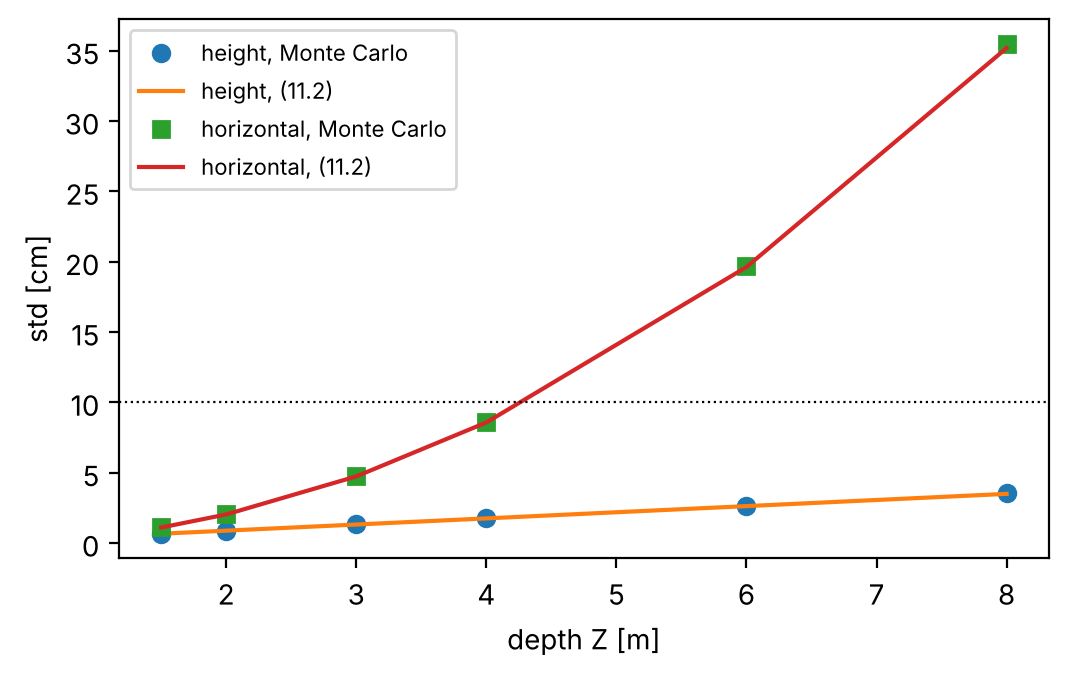

In [3]:
cam, fb, hc = S.stereo.cam, S.stereo.cam.fx * S.stereo.baseline, 0.8
prior = maps.nominal_ground(sim.camera_mount())
Zs = np.array([1.5, 2, 3, 4, 6, 8])
mc_h, mc_p, th_h, th_p = [], [], [], []
for Z in Zs:
    # a ground point straight ahead at depth Z: q = Z r with n^T q = d
    # solve for y (image row) on the nominal plane with x = 0
    n, d = prior.n, prior.d
    y = (d / Z - n[2]) / n[1]
    r = np.array([0.0, y, 1.0])
    disp = fb / Z + rng.normal(0, SIGMA_D, 100_000)
    Q = (fb / disp)[:, None] * r
    dq = Q - Z * r
    h = dq @ n
    par = dq - h[:, None] * n
    mc_h.append(h.std()); mc_p.append(np.sqrt(np.mean(np.sum(par**2, 1))))
    th_h.append(hc * Z * SIGMA_D / fb); th_p.append(Z**2 * SIGMA_D / fb * np.sqrt(r @ r - (hc / Z)**2))
plt.figure(figsize=(6, 3.5))
plt.plot(Zs, 100 * np.array(mc_h), "o", label="height, Monte Carlo"); plt.plot(Zs, 100 * np.array(th_h), "-", label="height, (11.2)")
plt.plot(Zs, 100 * np.array(mc_p), "s", label="horizontal, Monte Carlo"); plt.plot(Zs, 100 * np.array(th_p), "-", label="horizontal, (11.2)")
plt.axhline(10, color="k", ls=":", lw=0.8); plt.xlabel("depth Z [m]"); plt.ylabel("std [cm]"); plt.legend(fontsize=8)
print("maximum range for a 10 cm cell (11.3):", np.sqrt(0.1 * fb / SIGMA_D))

## 3. The ground plane of a keyframe (Proposition 11.4)

RANSAC near the plane predicted by the camera mount, then a total-least-squares refit.

normal error 0.92 deg, camera height above plane 0.767 m (0.8 m above the soil, grass up to 8 cm)


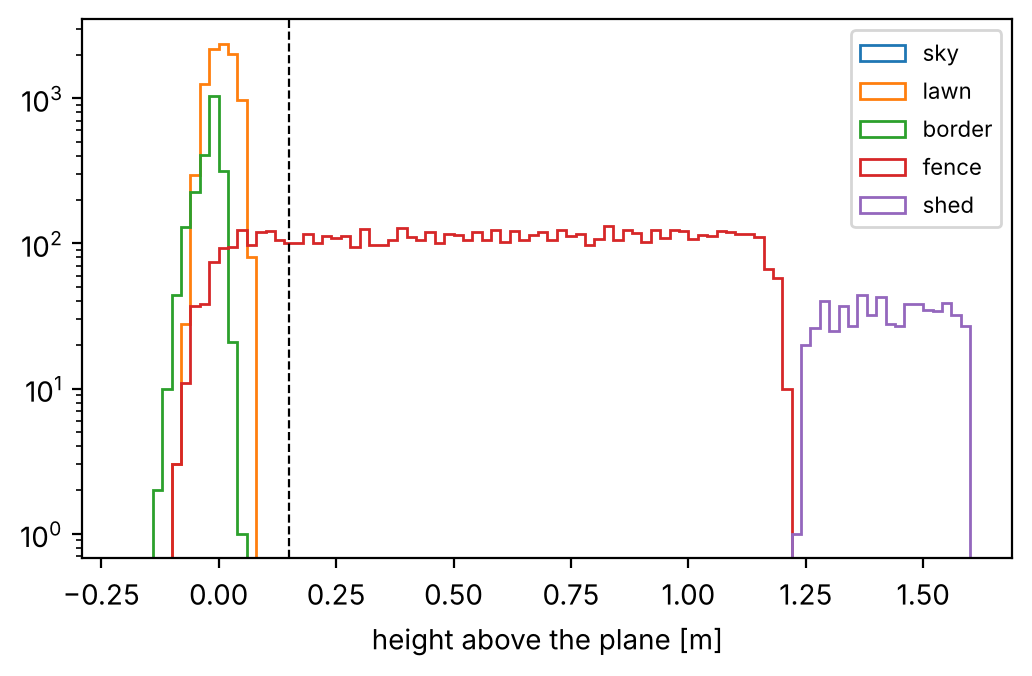

In [4]:
ok = np.isfinite(f.depth)
q = maps.stereo_points(f.uv[ok], f.depth[ok], S.stereo)
plane, inl = maps.ground_plane(q, prior, rng)
up = T[:3, :3].T @ np.array([0, 0, 1.0])
print(f"normal error {np.degrees(np.arccos(plane.n @ up)):.2f} deg, camera height above plane {-plane.d:.3f} m "
      f"(0.8 m above the soil, grass up to 8 cm)")
h = plane.height(q)
lab = f.label[ok]
plt.figure(figsize=(6, 3.5))
for k in np.unique(lab):
    sel = (q[:, 2] < 6)
    plt.hist(h[sel & (lab == k)], bins=np.linspace(-0.2, 1.6, 91), histtype="step", label=scene.LABELS[k])
plt.axvline(0.15, color="k", ls="--", lw=0.8); plt.yscale("log"); plt.xlabel("height above the plane [m]"); plt.legend(fontsize=8)

## 4. Log-odds and votes (Propositions 11.6 and 11.7)

A cell whose votes are right with probability $1-\epsilon$: how often is its label still wrong after $n$ votes?

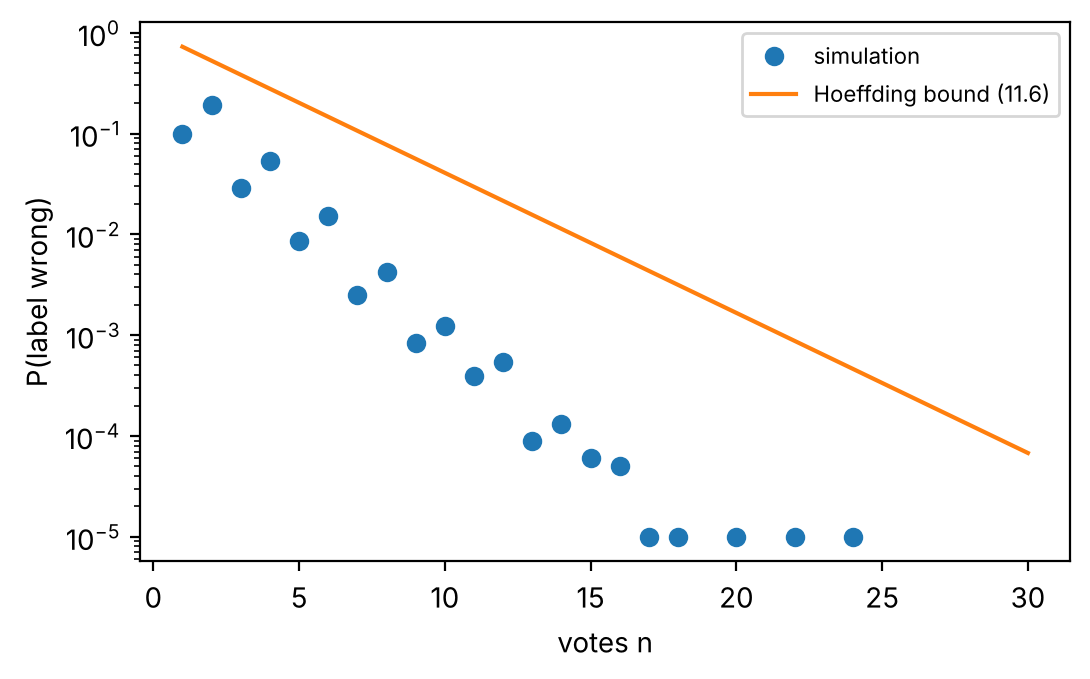

In [5]:
eps, a = 0.1, maps.logit(0.75)
ns = np.arange(1, 31)
votes = np.where(rng.random((100_000, 30)) < eps, a, -a)     # true state m = 0
wrong = (np.cumsum(votes, axis=1) >= 0).mean(axis=0)
plt.figure(figsize=(6, 3.5))
plt.semilogy(ns, wrong, "o", label="simulation"); plt.semilogy(ns, np.exp(-ns * (1 - 2 * eps)**2 / 2), "-", label="Hoeffding bound (11.6)")
plt.xlabel("votes n"); plt.ylabel("P(label wrong)"); plt.legend(fontsize=8)

## 5. Fusing the keyframes with three sets of poses

The keyframe observations are rendered at the true poses (the garden is what it is) and stored in each camera's frame;
the grid is then fused with the true, VO and pose-graph poses. The pose graph is the one of Chapter 10 (it takes a
little while).

true poses   {'lawn found': 0.982136876186223, 'obstacle -> mowable': 0, 'not lawn -> mowable': 0, 'false obstacle': 424}
VO poses     {'lawn found': 0.9436195154627666, 'obstacle -> mowable': 33, 'not lawn -> mowable': 316, 'false obstacle': 451}
pose graph   {'lawn found': 0.9653901976108072, 'obstacle -> mowable': 0, 'not lawn -> mowable': 0, 'false obstacle': 462}


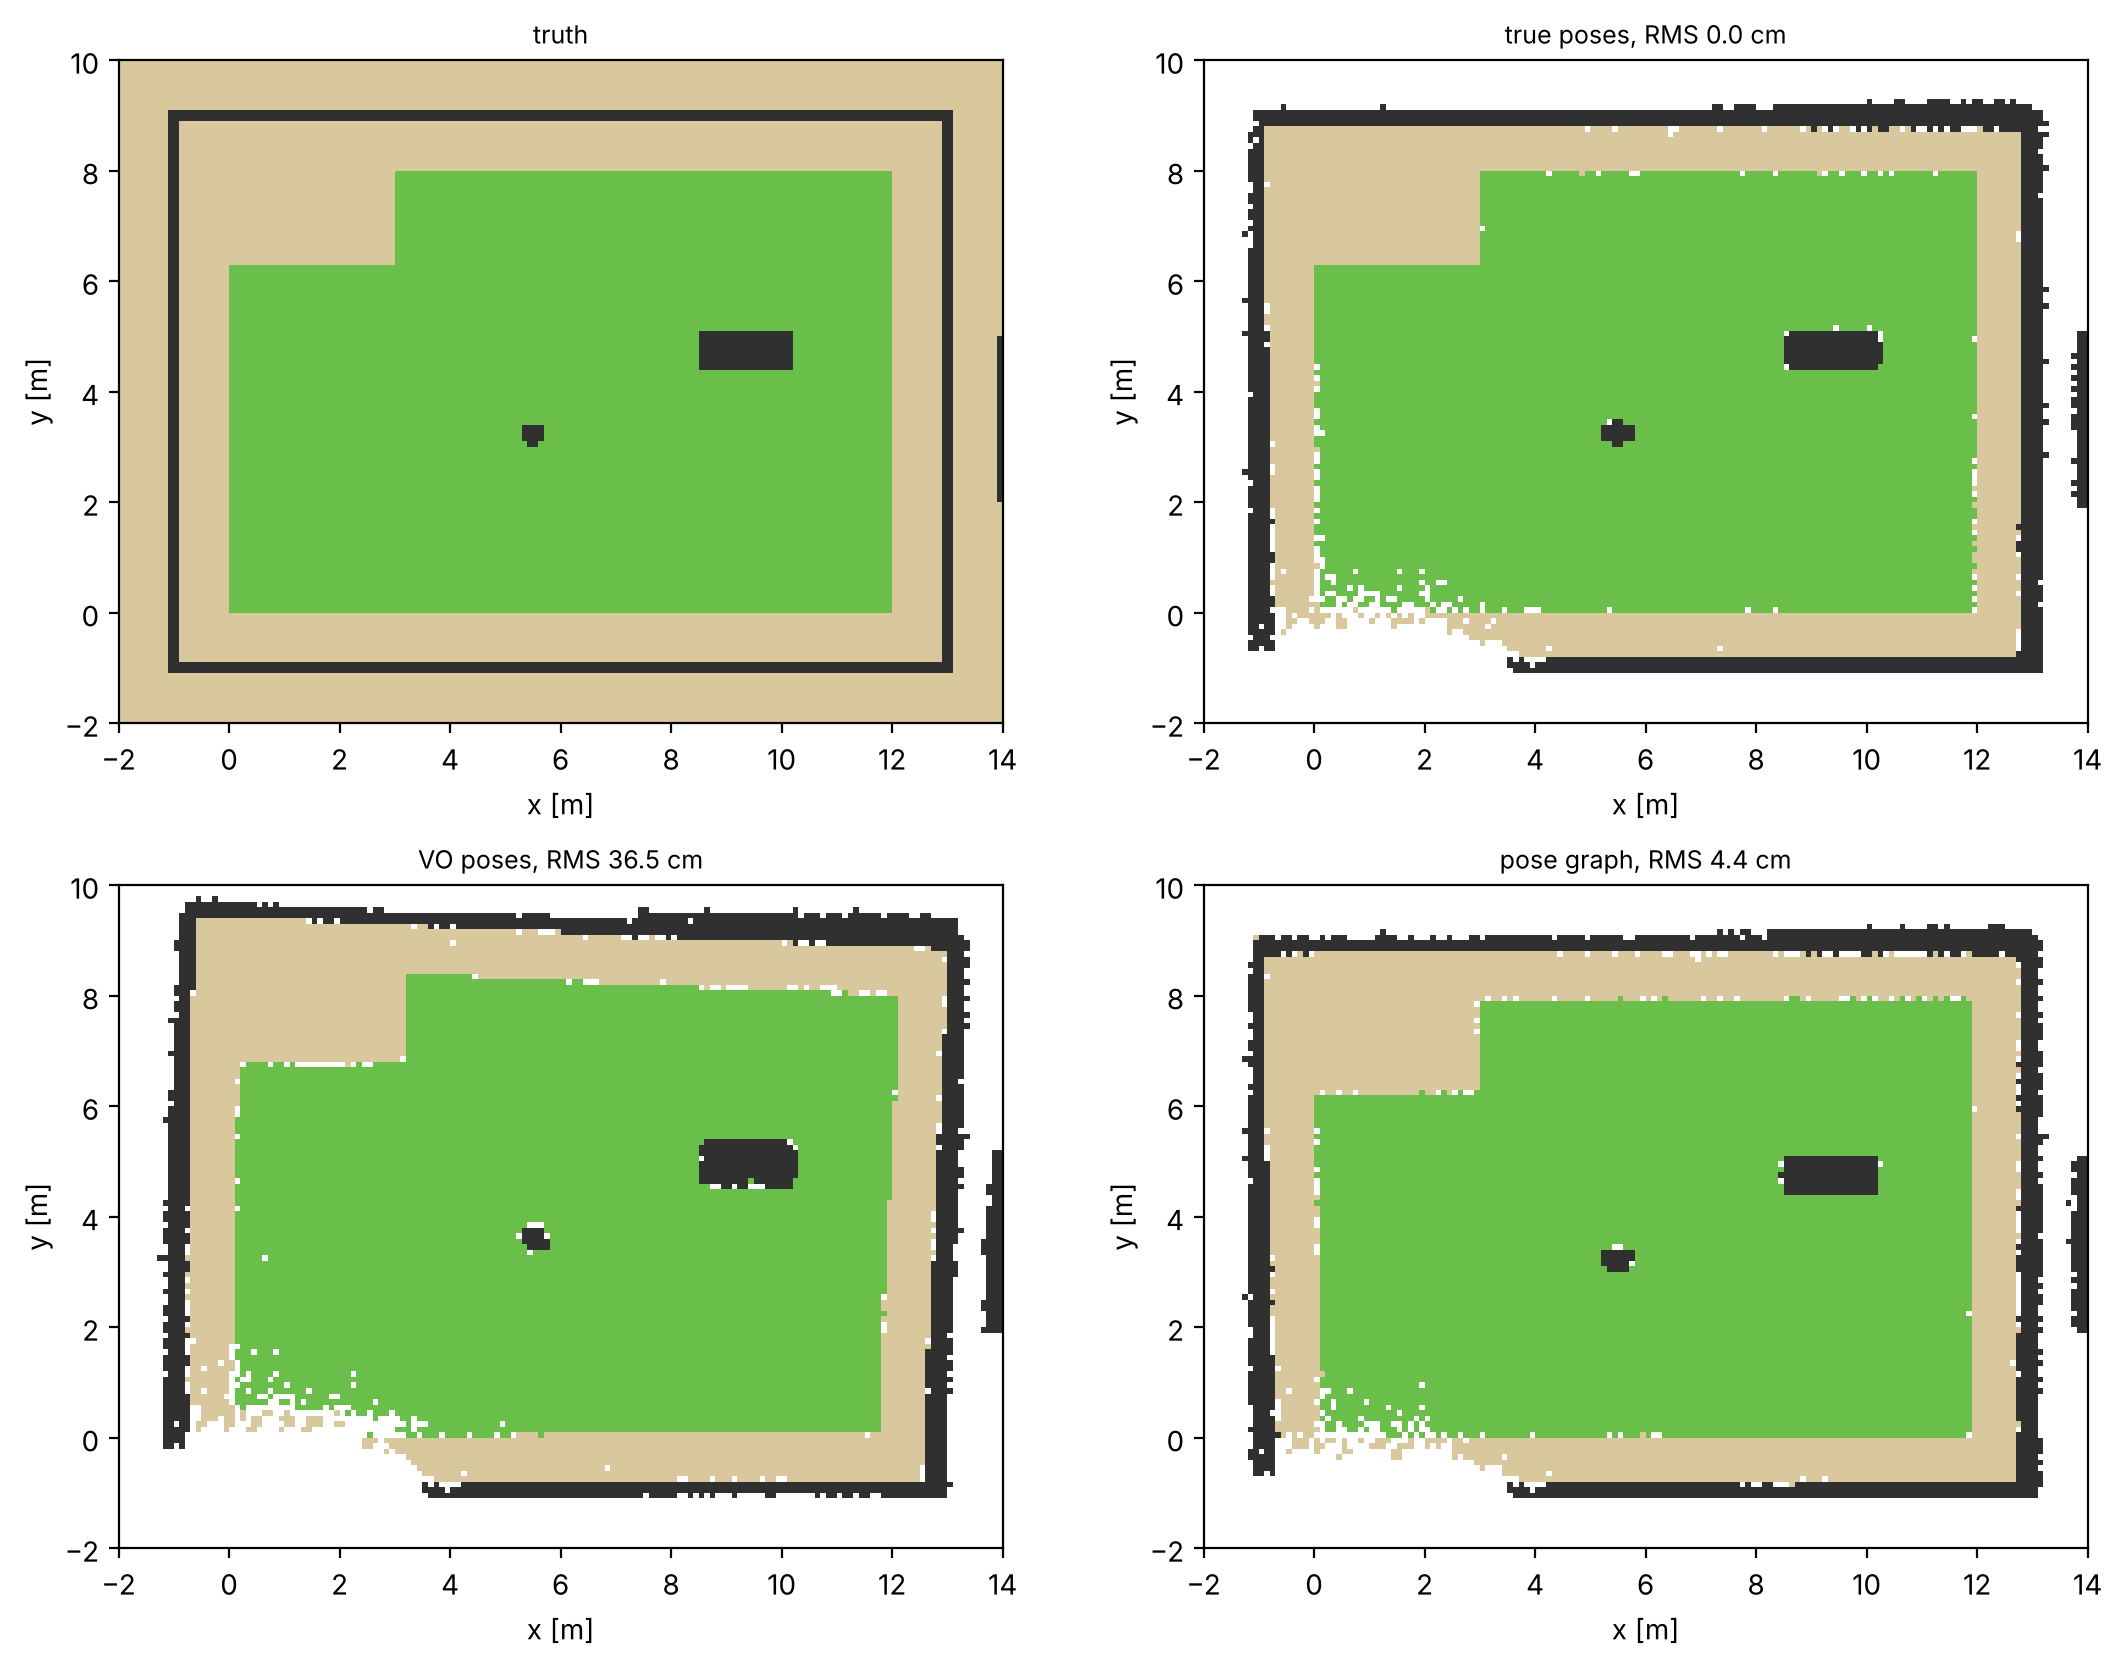

In [6]:
truth = garden.truth_grid(EXTENT, SPEC.res)
world, S, kfr, desc, P, G, _ = garden_keyframes()
clouds, _ = keyframe_clouds(garden, S.stereo, G, np.random.default_rng(11))
Q = corrected_poses(S.stereo, kfr, desc, P)
fig, axes = plt.subplots(2, 2, figsize=(11, 8.4))
draw(axes[0, 0], truth, "truth")
grids = {}
for a, (poses, name) in zip(axes.ravel()[1:], [(G, "true poses"), (P, "VO poses"), (Q, "pose graph")]):
    grids[name] = maps.fuse(SPEC, poses, clouds)
    cls = grids[name].classes()
    draw(a, cls, f"{name}, RMS {100 * rms(poses, G):.1f} cm")
    print(f"{name:12s}", scores(cls, truth))
fig.tight_layout()

## 6. Export to the Lawnmower planners

One planner cell is the blade's footprint (1 m here). If the Lawnmower package is installed
(`pip install -e path/to/Lawnmower`), its planners run directly on the export.

In [7]:
cls = grids["pose graph"].classes()
mow = maps.coarsen(cls, 10)
text = maps.to_lawn_text(mow, start=(3, 3))
print(text)
try:
    from lawnmower import Lawn, plan
    lawn = Lawn.from_string(text)
    for planner in ["boustrophedon", "stc"]:
        print(f"{planner:14s}", plan(lawn, planner).metrics.as_dict())
except ImportError:
    print("Lawnmower not installed")

++++++++++++++++++
++++++++++++++++++
++++++++++++++++++
++++++LLLLLLLL++++
++++++LLLLLLLLL+++
+++LLLLLLLL+++L+++
+++LLLLLLLL+++L+++
+++LLLLL+LLLLLL+++
+++LLLLLLLLLLL++++
++++SLLLLLLLLLL+++
+++++LLLLLLLLL++++
++++++++++++++++++
++++++++++++++++++
++++++++++++++++++

boustrophedon  {'coverage_%': 100.0, 'steps': 86, 'length': 88.9, 'turns': 23, 'turn_angle': 2430, 'revisits': 10, 'mean_run': 3.58, 'overhead': 1.132}
stc            {'coverage_%': 100.0, 'steps': 83, 'length': 85.5, 'turns': 44, 'turn_angle': 4545, 'revisits': 7, 'mean_run': 1.84, 'overhead': 1.092}


## Exercises

1. Raise the disparity noise to 0.5 px (`SIGMA_D`) and find the best maximum range again. Does (11.3) still predict it?
2. Move the flower bed (`garden.boxes[-1]`) after the first half of the run and fuse again: how many keyframes does the
   map need to forget it (Exercise 11.3)?
3. Replace the per-keyframe ground plane by heights from the VO poses ($z$ in the world) and count the ground points
   classified as obstacles. Then tilt the lawn by 5° in the renderer: which method still works?